<a href="https://colab.research.google.com/github/HanHoHyeong/H3/blob/main/%EB%B9%85%EB%8D%B0%EC%9D%B4%ED%84%B0%EB%B6%84%EC%84%9D_%EA%B3%BC%EC%A0%9C4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import random
import time
import sys
import math
import mmh3

total_cnt = 120000
user_pool = [f"user_{i}" for i in range(40000)]

stream = [random.choice(user_pool) for _ in range(total_cnt)]

print(f"총 스트림 데이터 개수: {len(stream):,}")
print(f"데이터 샘플 확인: {stream[:5]}")

총 스트림 데이터 개수: 120,000
데이터 샘플 확인: ['user_42', 'user_4106', 'user_5610', 'user_34961', 'user_10011']


In [2]:
true_unique = len(set(stream))
print(f"실제 고유 원소 개수 (Ground Truth): {true_unique:,}")

class MyBloomFilter:
    def __init__(self, n, p):
        self.size = int(-(n * math.log(p)) / (math.log(2) ** 2))
        self.hash_count = int((self.size / n) * math.log(2))
        self.bit_arr = [0] * self.size

    def _get_indexes(self, val):
        for i in range(self.hash_count):
            yield abs(mmh3.hash(str(val), i)) % self.size

    def add(self, val):
        for idx in self._get_indexes(val):
            self.bit_arr[idx] = 1

    def __contains__(self, val):
        for idx in self._get_indexes(val):
            if self.bit_arr[idx] == 0:
                return False
        return True

    def memory_usage(self):
        return sys.getsizeof(self.bit_arr)


class MyHyperLogLog:
    def __init__(self, p=10):
        self.p = p
        self.m = 1 << p
        self.registers = [0] * self.m
        if self.m == 16: self.alpha = 0.673
        elif self.m == 32: self.alpha = 0.697
        elif self.m == 64: self.alpha = 0.709
        else: self.alpha = 0.7213 / (1 + 1.079 / self.m)

    def _get_rho(self, val):
        b = bin(val & 0xFFFFFFFF)[2:].zfill(32)
        for i, bit in enumerate(b):
            if bit == '1':
                return i + 1
        return 33

    def add(self, val):
        h = mmh3.hash(str(val), 100)
        idx = h & (self.m - 1)
        w = h >> self.p
        self.registers[idx] = max(self.registers[idx], self._get_rho(w))

    def count(self):
        est = self.alpha * (self.m ** 2) * sum(2.0 ** (-r) for r in self.registers) ** -1
        if est <= 2.5 * self.m:
            zeros = self.registers.count(0)
            if zeros > 0:
                est = self.m * math.log(self.m / zeros)
        return int(est)

    def memory_usage(self):
        return sys.getsizeof(self.registers)

print("알고리즘 클래스 정의 완료")

실제 고유 원소 개수 (Ground Truth): 38,037
알고리즘 클래스 정의 완료


In [3]:
import pandas as pd

hll_p_list = [8, 10, 12]
bf_err_list = [0.1, 0.01, 0.001]

result_data = []

for p_val in hll_p_list:
    t0 = time.time()
    hll = MyHyperLogLog(p=p_val)
    for x in stream:
        hll.add(x)
    t1 = time.time() - t0

    est = hll.count()
    err_rate = abs(est - true_unique) / true_unique * 100

    result_data.append({
        'Algorithm': f'HLL (p={p_val})',
        'True Count': true_unique,
        'Estimated': est,
        'Error (%)': round(err_rate, 2),
        'Memory (Bytes)': hll.memory_usage(),
        'Time (sec)': round(t1, 4)
    })

test_users = user_pool[:500]
fake_users = [f"fake_{i}" for i in range(500)]

for err in bf_err_list:
    t0 = time.time()
    bf = MyBloomFilter(n=40000, p=err)
    for x in stream:
        bf.add(x)
    t1 = time.time() - t0

    fp_cnt = sum(1 for f in fake_users if f in bf)
    fp_rate = (fp_cnt / len(fake_users)) * 100

    result_data.append({
        'Algorithm': f'BloomFilter (err={err})',
        'True Count': 0,
        'Estimated': f"FP: {fp_cnt}건",
        'Error (%)': round(fp_rate, 2),
        'Memory (Bytes)': bf.memory_usage(),
        'Time (sec)': round(t1, 4)
    })

df_res = pd.DataFrame(result_data)
df_res

,Algorithm,True Count,Estimated,Error (%),Memory (Bytes),Time (sec)
0,HLL (p=8),38037,10254883,26860.28,2104,0.1639
1,HLL (p=10),38037,40846081,107285.13,8248,0.1669
2,HLL (p=12),38037,536012,1309.19,32824,0.1719
3,BloomFilter (err=0.1),0,FP: 41건,8.20,1533664,0.1697
4,BloomFilter (err=0.01),0,FP: 2건,0.40,3067272,0.2825
5,BloomFilter (err=0.001),0,FP: 1건,0.20,4600880,0.4195


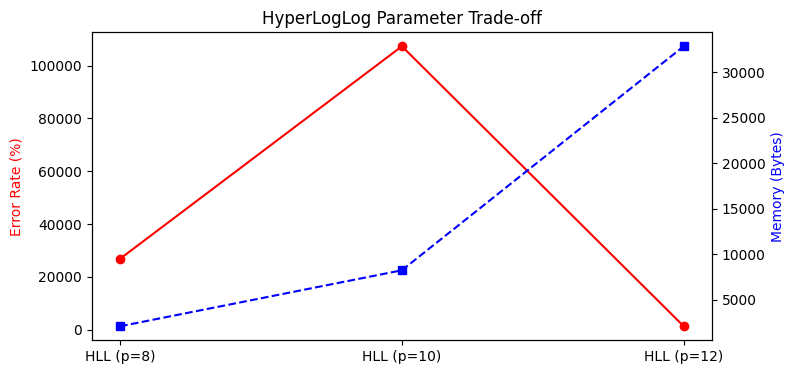

In [4]:
import matplotlib.pyplot as plt

hll_result = df_res[df_res['Algorithm'].str.contains('HLL')]

fig, ax1 = plt.subplots(figsize=(8, 4))

ax1.plot(hll_result['Algorithm'], hll_result['Error (%)'], color='red', marker='o', label='Error (%)')
ax1.set_ylabel('Error Rate (%)', color='red')

ax2 = ax1.twinx()
ax2.plot(hll_result['Algorithm'], hll_result['Memory (Bytes)'], color='blue', marker='s', linestyle='--', label='Memory')
ax2.set_ylabel('Memory (Bytes)', color='blue')

plt.title('HyperLogLog Parameter Trade-off')
plt.show()